# Bayesian Coin

- This notebook builds Bayesian inference on a coin-flip example, from the
  Bernoulli, binomial, and Beta distributions to an analytical posterior, a
  numerical posterior with `pymc`, and a decision with a loss function
- The pedagogical arc:
  - Bernoulli, binomial, and Beta distributions, with interactive widgets
    and parameter grids
  - Analytical solution: a Beta prior updated by streaming coin-flip data,
    and three different priors updated at once
  - Numerical solution with `pymc` for growing sample sizes ($N=4$, 20, 100),
    read with `arviz`, plus the Savage-Dickey ratio and the ROPE
  - Decision with a loss function: turning the posterior samples into a
    point estimate

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import preliz as pz
import pymc as pm
import scipy.stats as stats

WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import L07_01_bayesian_coin_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /venv/lib/python3.12/site-packages/ipykernel_launcher.py -f /root/.local/share/jupyter/runtime/kernel-f1bd734b-dace-4d0e-b68f-f1cf7a184667.json


# Part 1: Probability Distributions

## Cell 1.1: Bernoulli

**Goal**
- Build intuition for the Bernoulli distribution, a single trial with two
  outcomes
- $X \sim \text{Bernoulli}(p)$ means $P(X = 1) = p$ and
  $P(X = 0) = 1 - p$, $0 \leq p \leq 1$

**Description**
- Inputs
  - `n`: number of samples drawn, 1-50
  - `p`: success probability, 0-1

- Panels
  - `data`: printed array of `n` realizations, each 0 or 1

In [3]:
utils.cell1_1_sample_bernoulli_widget()

**Guided usage**
- Raise `p` from 0 toward 1, leaving `n` fixed
  - Observe the printed `data` shift from mostly 0s to mostly 1s: a coin
    flip is $X=1$ if heads, $X=0$ if tails, and `p` is the heads
    probability

**Implementation** `cell1_1_sample_bernoulli_widget()`
- Draws `n` samples from `scipy.stats.bernoulli(p)` and prints them

In [4]:
hintros.print_obj_info(utils.cell1_1_sample_bernoulli_widget)

- `cell1_1_sample_bernoulli_widget() -> None`  
  Sample from a Bernoulli(p) distribution and print the realizations.

https://github.com/GokuHashira/gpsaggese.github.io/blob/UmdTask778_Gokul/msml610/tutorials/L07_prob_programming/L07_01_bayesian_coin_utils.py#L40


## Cell 1.2: Binomial

**Goal**
- Build intuition for the binomial distribution, the count of successes
  over `trials` independent Bernoulli draws
- $P(X = k) = \binom{\text{trials}}{k} p^k (1 - p)^{\text{trials} - k}$

**Description**
- Inputs
  - `n`: number of samples drawn, 1-50
  - `trials`: trials per sample, 1-100
  - `p`: success probability, 0-1

- Panels
  - `data`: printed array of `n` realizations, each a count in
    `[0, trials]`

In [5]:
utils.cell1_2_sample_binomial_widget()

**Guided usage**
- Raise `trials` from 1 toward 100, leaving `p` fixed
  - Observe the printed counts spread over a wider range: e.g. flipping
    a fair coin 10 times, the number of heads follows `Binomial(10, 0.5)`

**Implementation** `cell1_2_sample_binomial_widget()`
- Draws `n` samples from `scipy.stats.binom(trials, p)` and prints them

In [6]:
hintros.print_obj_info(utils.cell1_2_sample_binomial_widget)

- `cell1_2_sample_binomial_widget() -> None`  
  Sample from a Binomial(trials, p) distribution and print the...

https://github.com/GokuHashira/gpsaggese.github.io/blob/UmdTask778_Gokul/msml610/tutorials/L07_prob_programming/L07_01_bayesian_coin_utils.py#L85


## Cell 1.3: Interactive binomial PMF

**Goal**
- Explore the binomial PMF's shape directly through `preliz`'s own
  interactive widget

**Implementation** `pz.Binomial(p, n).plot_interactive(**params)`
- `preliz` builds and displays its own sliders for `p` and `n`; `kind` and
  `interval` control how the distribution is summarized

In [7]:
# Probability of k successes on N trials flipping a coin with p success.
params = {
    # "kind": "cdf",
    "kind": "pdf",
    "pointinterval": False,
    "interval": "hdi",  # Highest density interval.
    # "interval": "eti",  # Equally tailed interval.
    "xy_lim": "auto",
}
pz.Binomial(p=0.5, n=5).plot_interactive(**params)

interactive(children=(IntSlider(value=5, description='n (0, inf)', max=15, style=SliderStyle(description_width…

## Cell 1.4: Binomial distribution grid

**Goal**
- Compare the binomial PMF's shape across a grid of `n` and `p` values at
  once

**Implementation** `plot_binomial()`
- Plots `stats.binom(n, p).pmf(x)` for every combination of 3 `n` values
  and 5 `p` values, one subplot each

In [8]:
import os
os.environ["CSFY_GIT_ROOT_PATH"] = "/tmp/msml610"

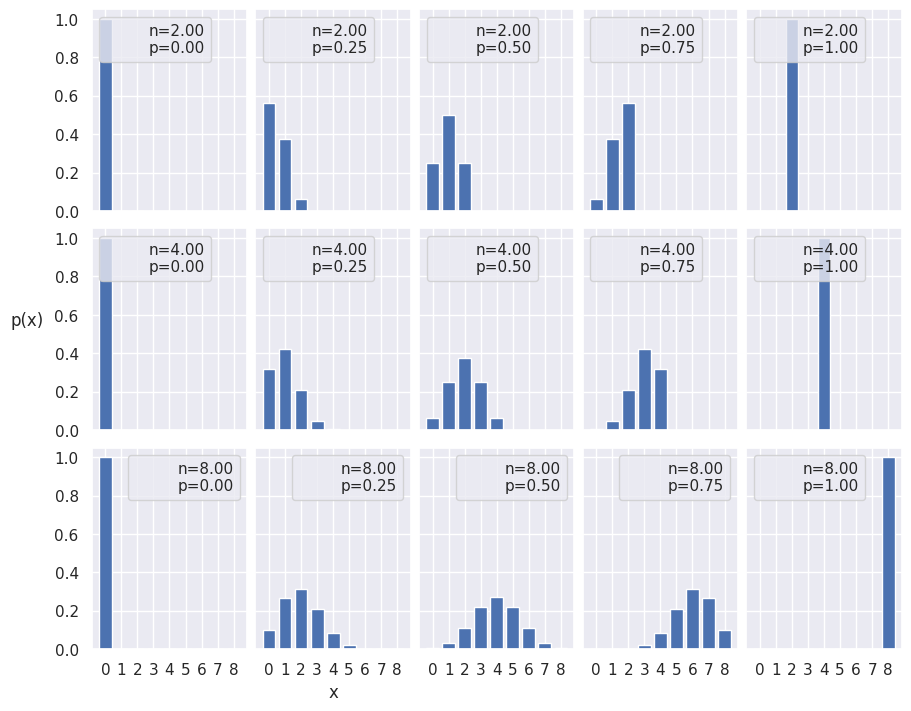

In [9]:
utils.plot_binomial()

## Cell 1.5: Beta

**Goal**
- Build intuition for the Beta distribution, a continuous distribution on
  $[0, 1]$ used to model a probability or proportion
- `a` is the "success" shape parameter, `b` is the "failure" shape
  parameter: `a` > `b` skews the density toward 1, `a` = `b` centers it
  on 0.5

**Description**
- Inputs
  - `n`: number of samples drawn, 1-50
  - `a`: alpha shape parameter, 0.1-10
  - `b`: beta shape parameter, 0.1-10

- Panels
  - `data`: printed array of `n` realizations in `[0, 1]`

In [10]:
utils.cell1_5_sample_beta_widget()

**Guided usage**
- Set `a` well above `b`, then well below it
  - Observe the printed samples cluster near 1 in the first case and
    near 0 in the second: `a` > `b` skews toward 1, `a` < `b` skews
    toward 0

**Implementation** `cell1_5_sample_beta_widget()`
- Draws `n` samples from `scipy.stats.beta(a, b)` and prints them

In [11]:
hintros.print_obj_info(utils.cell1_5_sample_beta_widget)

- `cell1_5_sample_beta_widget() -> None`  
  Sample from a Beta(a, b) distribution and print the realizations.

https://github.com/GokuHashira/gpsaggese.github.io/blob/UmdTask778_Gokul/msml610/tutorials/L07_prob_programming/L07_01_bayesian_coin_utils.py#L181


## Cell 1.6: Interactive beta PMF

**Goal**
- Explore the Beta density's shape directly through `preliz`'s own
  interactive widget

**Implementation** `pz.Beta(alpha, beta).plot_interactive(**params)`
- `preliz` builds and displays its own sliders for `alpha` and `beta`

In [12]:
params = {
    # "kind": "cdf",
    "kind": "pdf",
    "pointinterval": False,
    "interval": "hdi",  # Highest density interval.
    # "interval": "eti",  # Equal tailed interval.
    "xy_lim": "auto",
}
alpha = 3.0
beta = 1.0
pz.Beta(alpha=alpha, beta=beta).plot_interactive(**params)

interactive(children=(FloatSlider(value=3.0, description='alpha (0, inf)', max=13.0, min=2.220446049250313e-16…

## Cell 1.7: Beta distribution grid

**Goal**
- Compare the Beta density's shape across a grid of `alpha` and `beta`
  values at once

**Implementation** `plot_beta()`
- Plots `stats.beta(a, b).pdf(x)` for every combination of 4 `alpha`
  values and 4 `beta` values, one subplot each

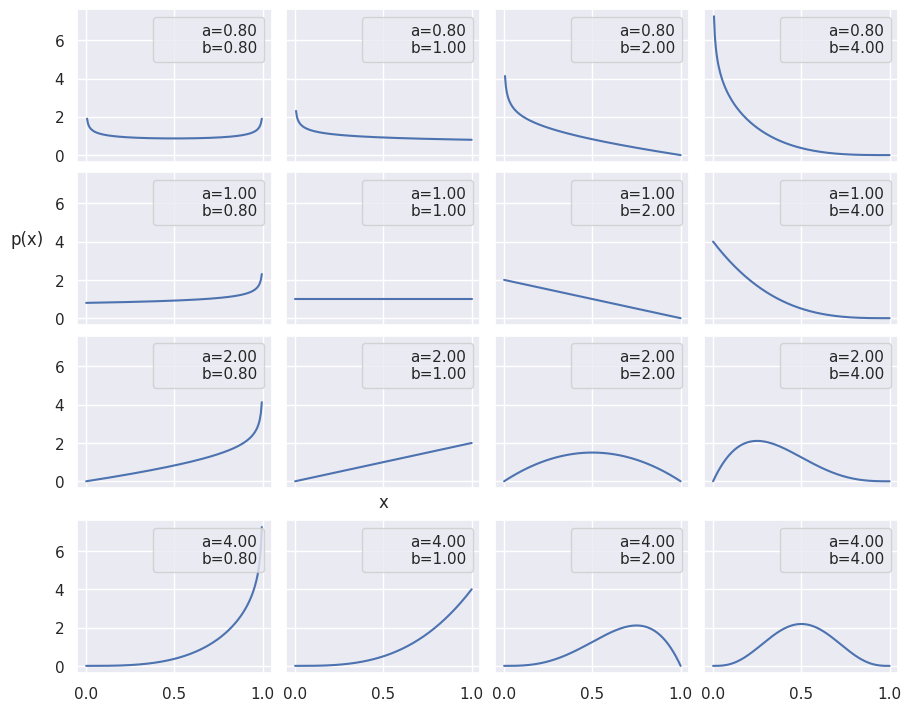

In [13]:
utils.plot_beta()

# Part 2: Coin Example, Analytical Solution

## Cell 2.1: Beta prior updated by streaming data

**Goal**
- Watch a single Beta prior turn into a posterior as more coin-flip data
  arrives, one trial count at a time
- `prior=(1, 1)` is uniform, `(20, 20)` looks Gaussian centered on 0.5,
  `(1, 4)` looks exponential centered near 0

**Description**
- Inputs
  - `seed`: random seed for the generated data
  - `theta (true)`: the true, otherwise-unknown success probability
  - `n_trials`: comma-separated trial counts to step through
  - `a`, `b`: the prior's Beta shape parameters
  - `Index`/play button: which `n_trials` entry is shown

- Panels
  - `Posterior after N=... trials, y=... heads`: the posterior
    density, with `theta (true)` marked
  - `Comments`: current parameters and the resulting posterior
    distribution

In [14]:
utils.beta_prior_interactive()

**Guided usage**
- Set `a`/`b` to `1, 1` (uniform prior), then step `Index` forward
  - Observe the posterior widen out then narrow around `theta (true)` as
    `N` grows
- Compare `a`/`b` = `1, 1` against `20, 20` at the same `Index`
  - Observe the strong `(20, 20)` prior barely moves at low `N`, while
    the uniform prior is dominated by the data almost immediately

**Implementation** `beta_prior_interactive()`
- Generates binomial counts $y \sim \text{Binomial}(N, \theta)$ at each
  `n_trials` entry with `_generate_data()`
- Plots the Beta(`a`+y, `b`+N-y) posterior density for the trial count at
  `Index`, steppable via the play button

In [15]:
hintros.print_obj_info(utils.beta_prior_interactive)

- `beta_prior_interactive() -> None`  
  Create an interactive Beta-prior posterior-update visualization.

https://github.com/GokuHashira/gpsaggese.github.io/blob/UmdTask778_Gokul/msml610/tutorials/L07_prob_programming/L07_01_bayesian_coin_utils.py#L327


## Cell 2.2: Updating three priors at once

**Goal**
- Compare three different Beta priors, uniform, Gaussian-like, and
  exponential-like, updated by the same growing dataset side by side

**Implementation** `update_prior()`
- Fixes `theta_real = 0.35` and a shared sequence of `n_trials`/observed
  head counts
- Plots all three priors' posteriors at each trial count in one grid, so
  every prior can be compared at the same amount of data

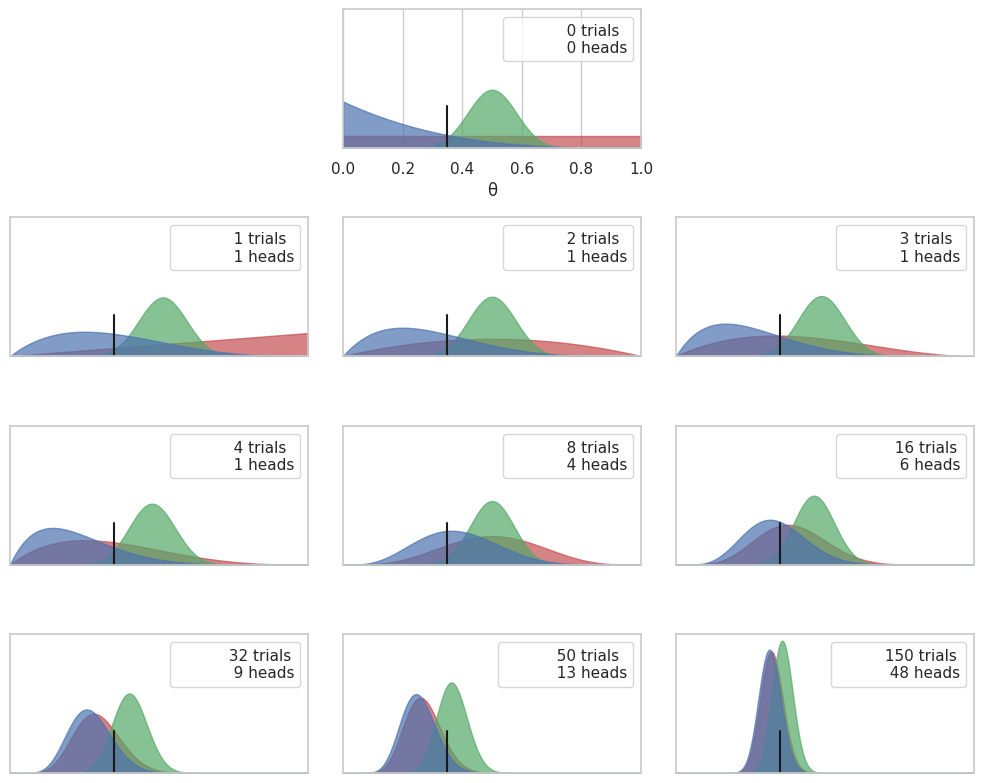

In [16]:
utils.update_prior()

- All three posteriors converge toward the same spike at `theta_real` as
  `N` grows, regardless of how different the priors started
- The Bayesian update replaces "guess and check" with an explicit rule
  for how a prior belief and new data combine into a posterior belief

# Part 3: Coin Example, Numerical Solution

- It's a synthetic example!
  - Assume you know the true value of $\theta$ (not true in general)

- **Workflow**
  - Model the prior $\theta$ and the likelihood $Y \mid \theta$
    \begin{equation*}
      \begin{cases}
      \theta \sim \text{Beta}(\alpha = 1, \beta = 1) \\
      Y \sim \text{Binomial}(n = 1, p = \theta) \\
      \end{cases}
    \end{equation*}
  - Observe samples of the variable $Y$
  - Run inference
  - Generate samples of the posterior
  - Summarize the posterior
    - E.g., Highest-Posterior Density (HPD)

## Cell 3.1: Fitting the model with N=4

**Goal**
- Fit the model above to `N=4` synthetic observations, and read the
  fitted posterior with `arviz`'s trace, summary, rank-bar, and
  posterior plots

**Implementation**
- Builds `model1` with a `Beta(1, 1)` prior and a `Bernoulli` likelihood
  observing `data1`, then draws posterior samples with `pm.sample()`
  (PyMC's NUTS sampler, 4 chains)
- `az.plot_trace()`/`az.summary()`/`az.plot_posterior()` summarize the
  resulting `idata1`

In [17]:
# Generate data from ground truth model.
np.random.seed(123)
n = 4
# Unknown value.
theta_real = 0.35
# Generate some observational data.
data1 = stats.bernoulli.rvs(p=theta_real, size=n)
print("data1=", data1)

data1= [1 0 0 0]


In [18]:
# Build PyMC model matching the mathematical model.
with pm.Model() as model1:
    # Prior.
    theta = pm.Beta("theta", alpha=1.0, beta=1.0)
    # Likelihood.
    y = pm.Bernoulli("y", p=theta, observed=data1)
    # (Numerical) Inference to estimate the posterior distribution through samples.
    idata1 = pm.sample(1000, random_seed=123)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


INFO  NUTS: [theta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


INFO  Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


array([[<Axes: title={'center': 'theta'}>,
        <Axes: title={'center': 'theta'}>]], dtype=object)

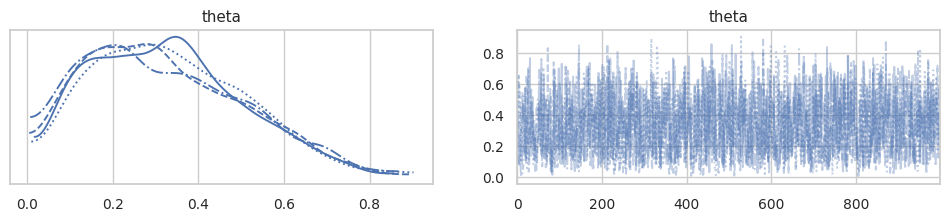

In [19]:
# Trace plot: one row per parameter, KDE (left) and chains (right).
az.plot_trace(idata1)

- No trace diverges, and the 4 chains mix well
- The KDE for `theta` should resemble a Beta density

In [20]:
# Numerical summary: mean, std dev, and HDI.
display(az.summary(idata1, kind="stats"))

,mean,sd,hdi_3%,hdi_97%
theta,0.326,0.178,0.04,0.654


- $E[\hat{\theta}] \approx 0.324$
- $\Pr(\hat{\theta} \in [0.031, 0.653]) = 0.94$

array([[<Axes: title={'center': 'theta'}>,
        <Axes: title={'center': 'theta'}, xlabel='Rank (all chains)', ylabel='Chain'>]],
      dtype=object)

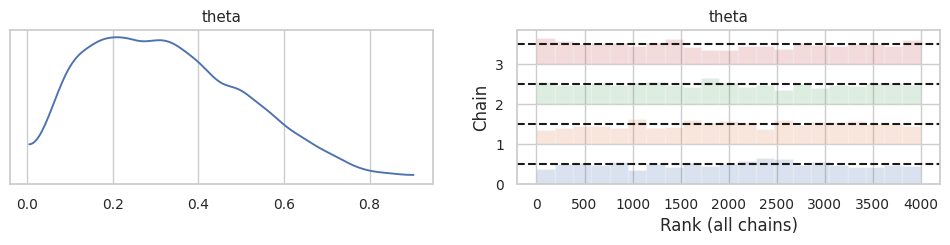

In [21]:
# Rank-bar diagnostic: flat bars indicate good mixing across chains.
az.plot_trace(idata1, kind="rank_bars", combined=True)

<Axes: title={'center': 'theta'}>

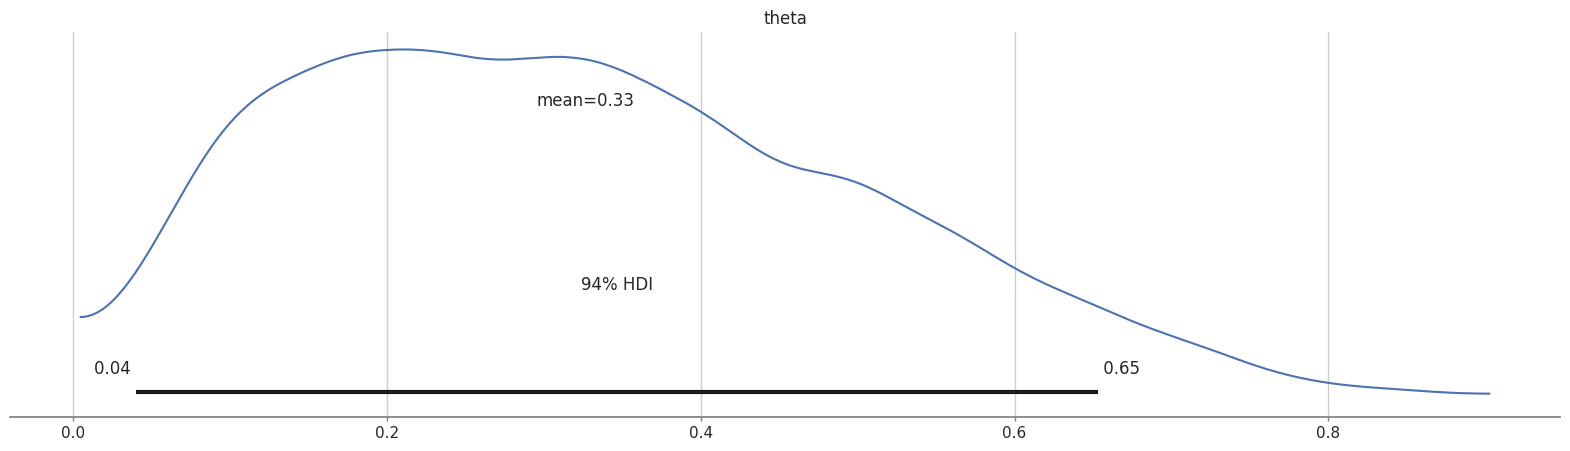

In [22]:
# Posterior density with the mean and HDI annotated.
az.plot_posterior(idata1)

## Cell 3.2: More data (N=20)

**Goal**
- Repeat Cell 3.1 with `N=20` observations, and see the posterior
  sharpen around `theta_real` as more data arrives

**Implementation**
- Same `Beta(1, 1)`/`Bernoulli` model as `model1`, refit on 20
  observations as `model2`

In [23]:
np.random.seed(123)
n = 20
# Unknown value.
theta_real = 0.35
# Generate some observational data.
data2 = stats.bernoulli.rvs(p=theta_real, size=n)
print("data2=", data2)

data2= [1 0 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0]


In [24]:
with pm.Model() as model2:
    # Prior.
    theta = pm.Beta("theta", alpha=1.0, beta=1.0)
    # Likelihood.
    y = pm.Bernoulli("y", p=theta, observed=data2)
    # (Numerical) Inference to estimate the posterior distribution through samples.
    idata2 = pm.sample(1000, random_seed=123)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


INFO  NUTS: [theta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


INFO  Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


In [25]:
display(az.summary(idata2, kind="stats"))

,mean,sd,hdi_3%,hdi_97%
theta,0.318,0.098,0.142,0.498


<Axes: title={'center': 'theta'}>

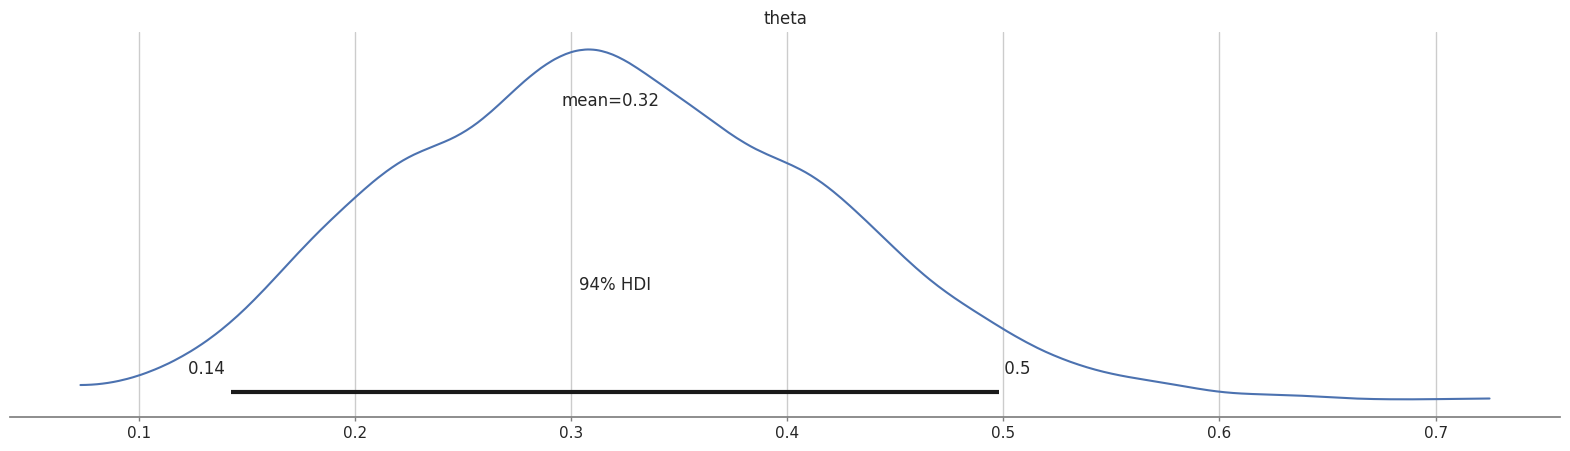

In [26]:
az.plot_posterior(idata2)

## Cell 3.3: Even more data (N=100)

**Goal**
- Repeat Cell 3.1 with `N=100` observations, to see the posterior
  sharpen even further

**Implementation**
- Same `Beta(1, 1)`/`Bernoulli` model as `model1`, refit on 100
  observations as `model3`

In [27]:
np.random.seed(123)
n = 100
# Unknown value.
theta_real = 0.35
# Generate some observational data.
data3 = stats.bernoulli.rvs(p=theta_real, size=n)
print("data3=", data3)

data3= [1 0 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 1
 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 0 0 0]


In [28]:
with pm.Model() as model3:
    # Prior.
    theta = pm.Beta("theta", alpha=1.0, beta=1.0)
    # Likelihood.
    y = pm.Bernoulli("y", p=theta, observed=data3)
    # (Numerical) Inference to estimate the posterior distribution through samples.
    idata3 = pm.sample(1000, random_seed=123)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


INFO  NUTS: [theta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


INFO  Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


In [29]:
display(az.summary(idata3, kind="stats"))

,mean,sd,hdi_3%,hdi_97%
theta,0.304,0.047,0.215,0.388


<Axes: title={'center': 'theta'}>

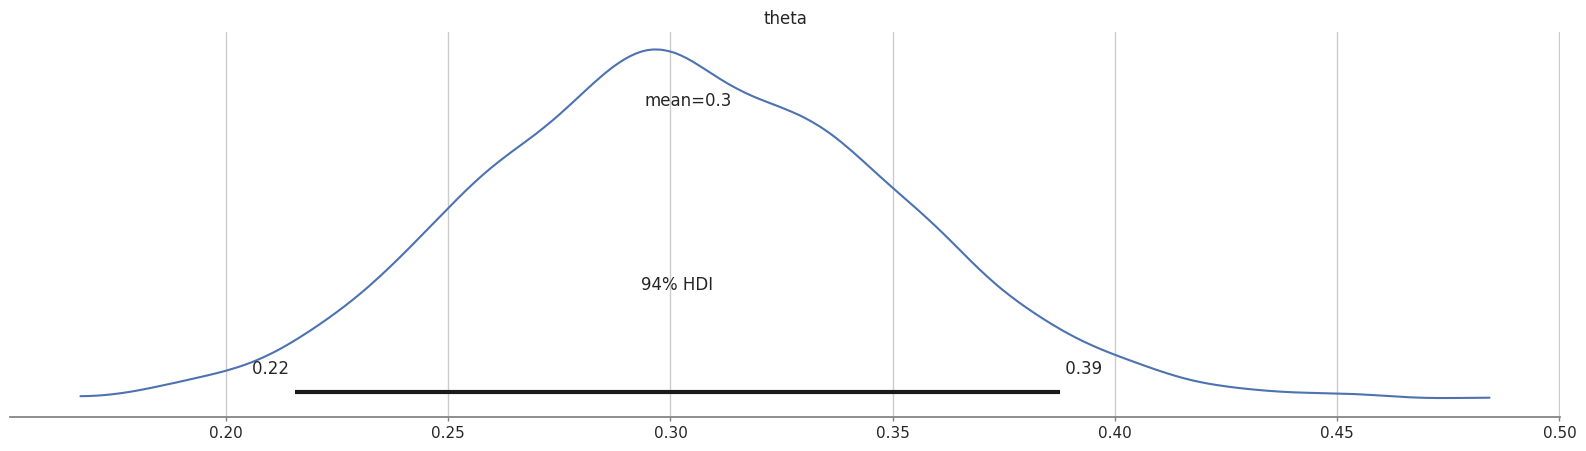

In [30]:
az.plot_posterior(idata3)

## Cell 3.4: Savage-Dickey ratio

**Goal**
- Test the point hypothesis $\theta = 0.5$ against each of the three
  fitted posteriors via the Savage-Dickey density ratio

**Implementation**
- `az.plot_bf()` compares the posterior density at `ref_val=0.5` against
  a uniform prior, for `idata1`, `idata2`, and `idata3` in turn

arviz - WARNING - The reference value is outside of the posterior. This translate into infinite support for H1, which is most likely an overstatement.


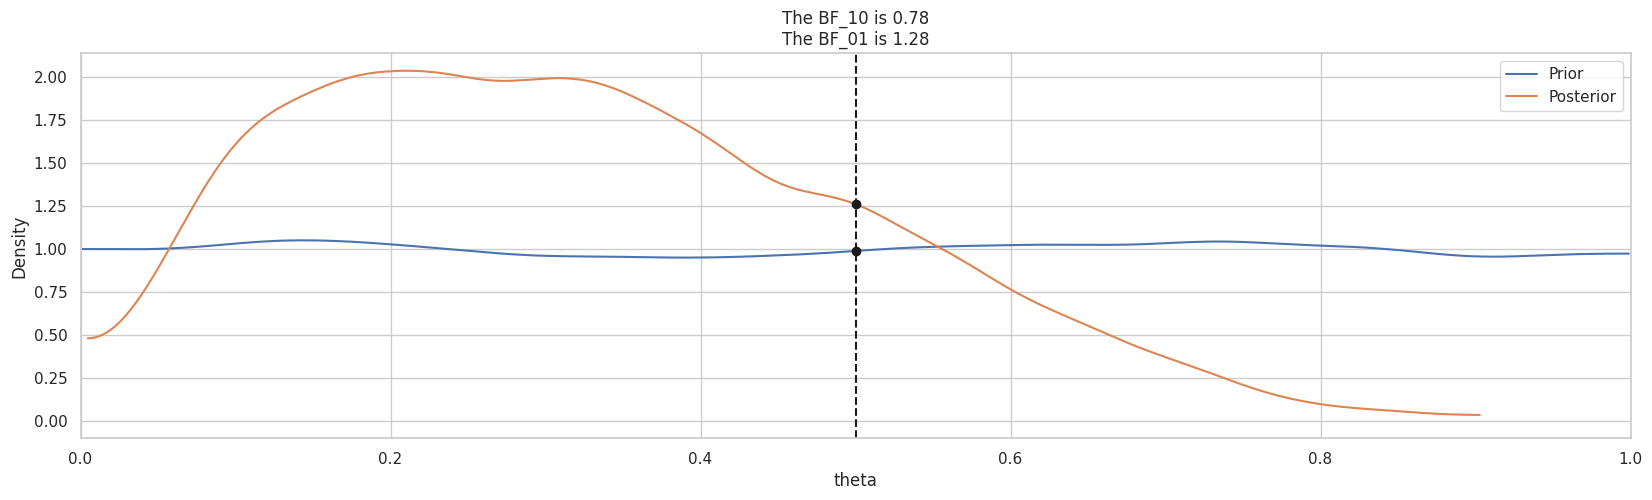

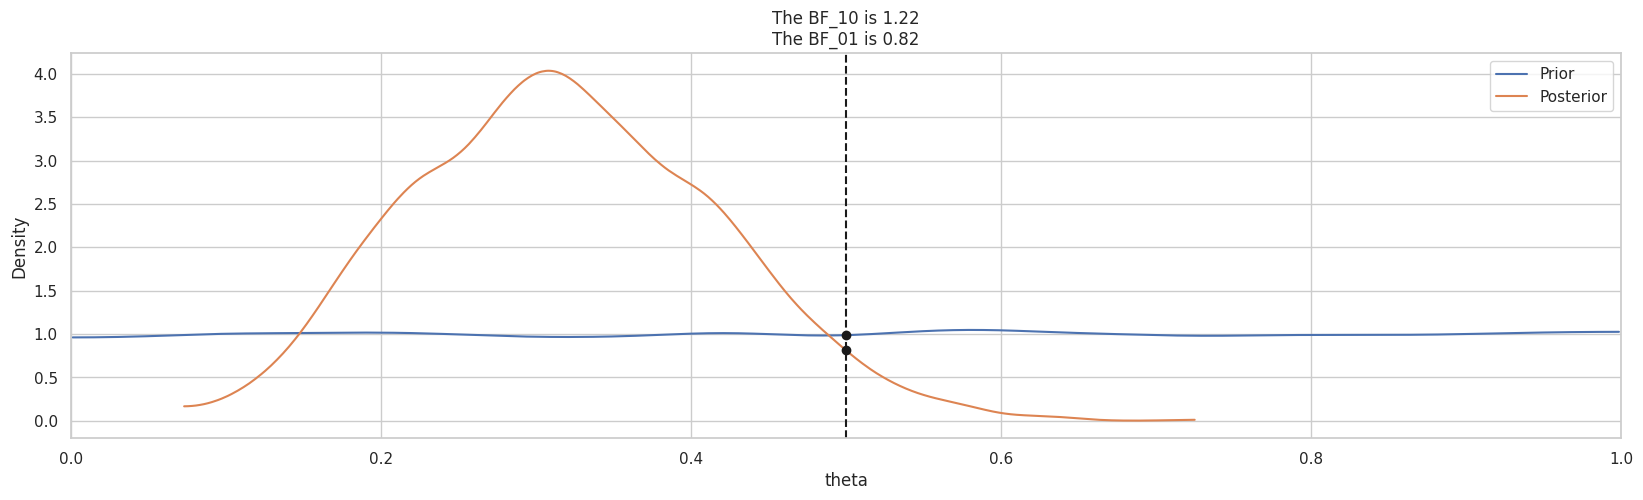

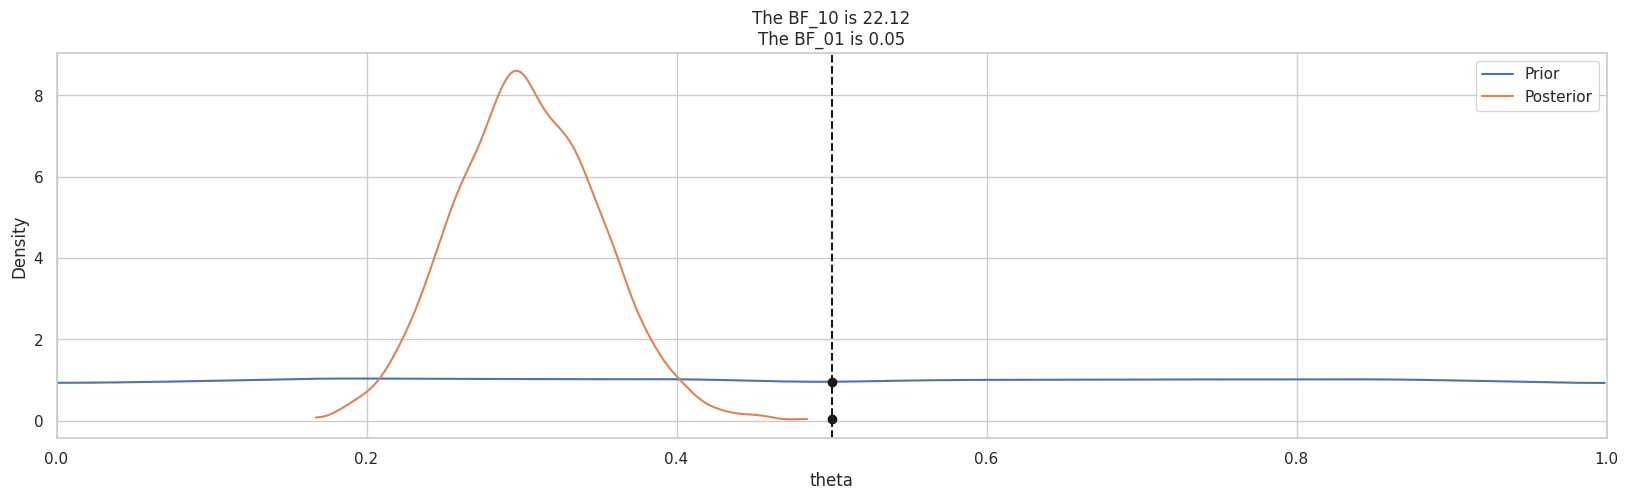

In [31]:
for idata in [idata1, idata2, idata3]:
    az.plot_bf(
        idata,
        var_name="theta",
        prior=np.random.uniform(0, 1, 10000),
        ref_val=0.5,
    )
    plt.xlim(0, 1)

## Cell 3.5: ROPE

**Goal**
- Test whether $\theta$ plausibly equals 0.5 using a Region Of Practical
  Equivalence (ROPE) instead of a single point

**Implementation**
- `az.plot_posterior()` shades the `[0.45, 0.55]` ROPE and reports the
  fraction of the posterior it contains, for each fitted `idata`

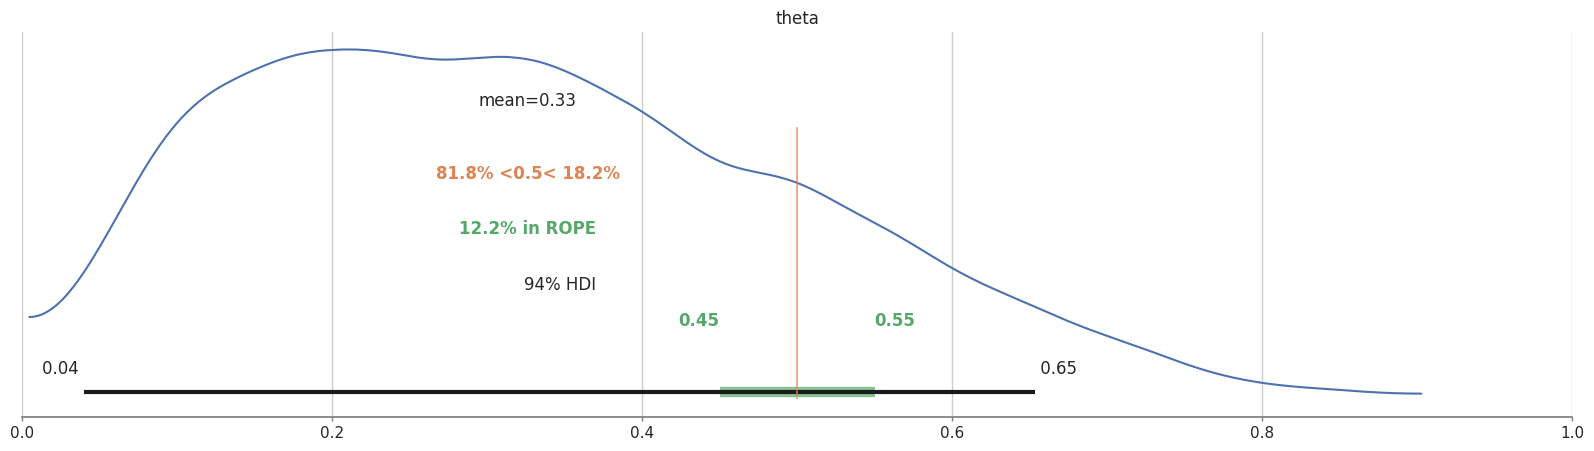

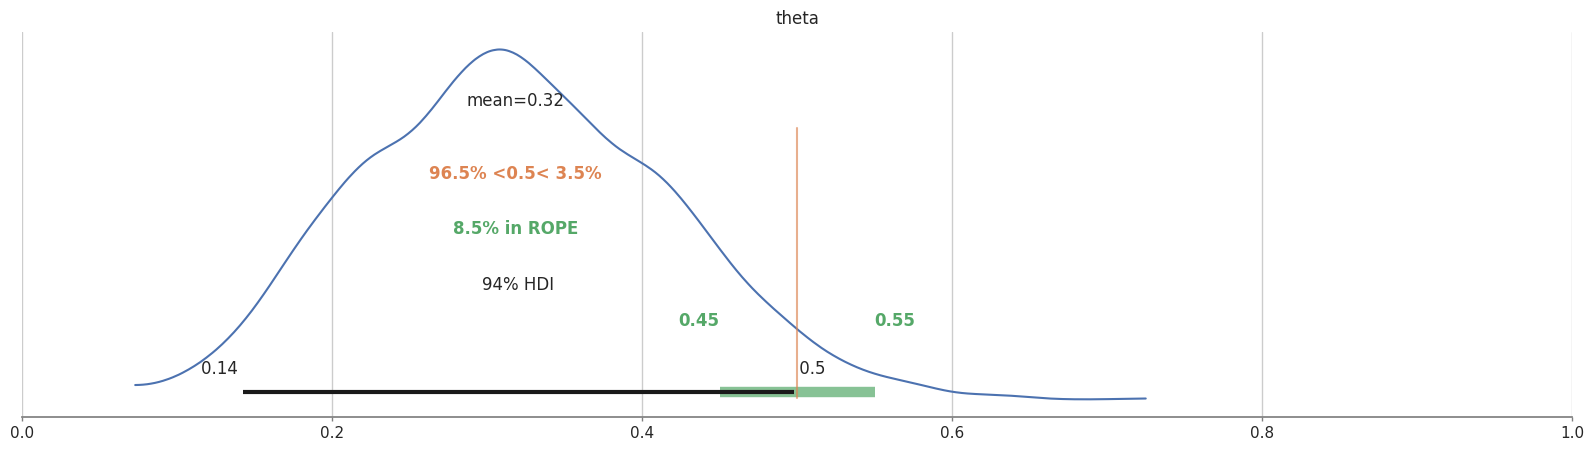

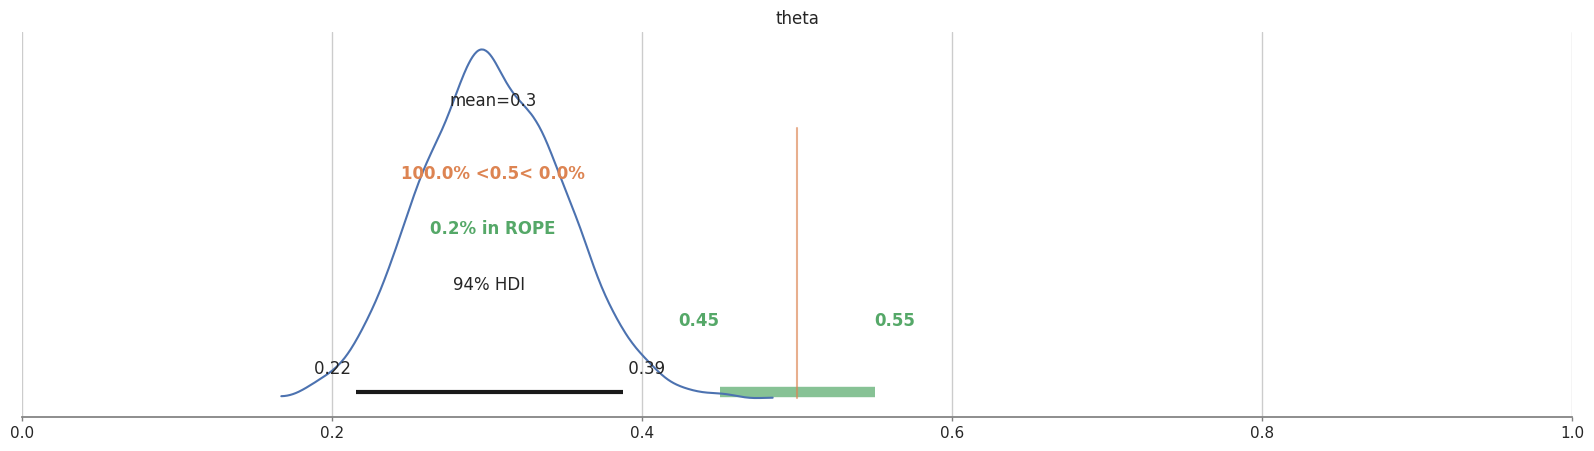

In [32]:
for idata in [idata1, idata2, idata3]:
    az.plot_posterior(idata, rope=[0.45, 0.55], ref_val=0.5)
    plt.xlim(0, 1)

# Part 4: Decision With a Loss Function

## Cell 4.1: Minimizing a loss function

**Goal**
- Turn a posterior into a point estimate by minimizing expected loss,
  instead of just reporting the posterior mean

**Implementation** `plot_loss(grid, loss_func)`
- Plots the chosen `loss_func` (squared, absolute, asymmetric, or sine)
  against a candidate-estimate grid

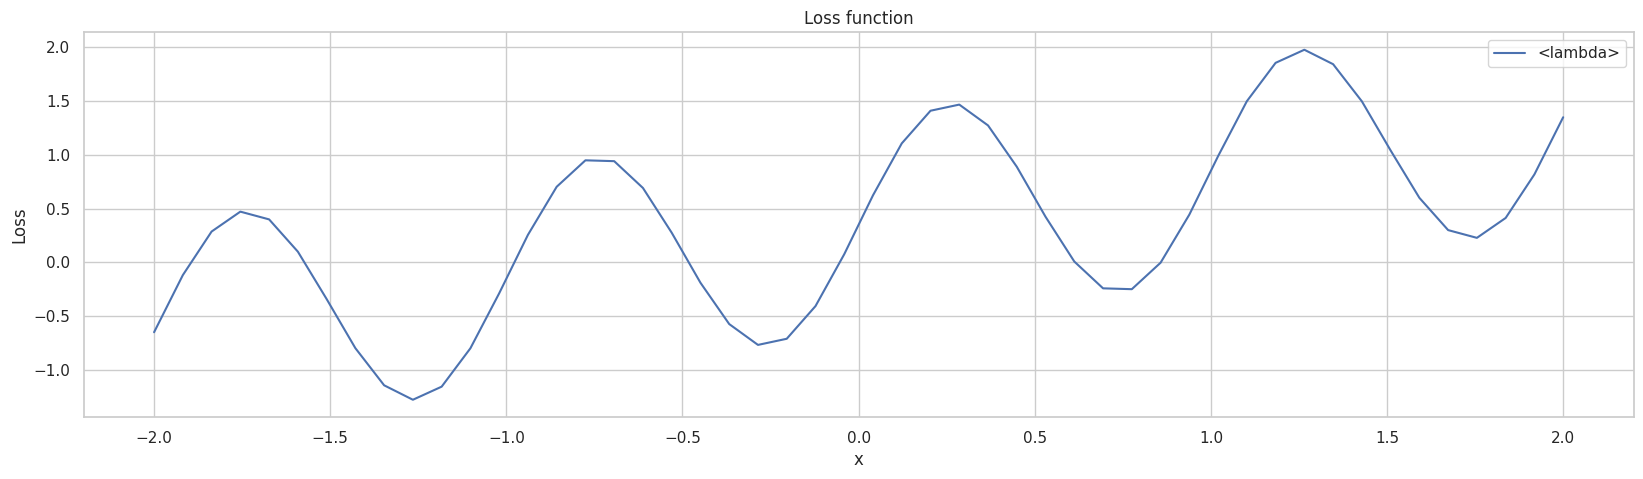

In [33]:
# loss_func = lambda x: utils.squared_loss(x, theta_real)
# loss_func = lambda x: utils.abs_loss(x, theta_real)
# loss_func = lambda x: utils.asymmetric_loss(x, theta_real)
loss_func = lambda x: utils.sin_loss(x, theta_real)

grid = np.linspace(-2.0, 2.0, 50)
utils.plot_loss(grid, loss_func)

## Cell 4.2: Posterior samples as a distribution

**Goal**
- Look at the raw posterior draws for `theta` directly: as a sequence,
  as a trace, and as a density

**Implementation**
- Extracts the `theta` column from `idata1.to_dataframe()` and plots it
  as a trace and a KDE

In [34]:
theta_draws = idata1.to_dataframe()[("posterior", "theta")]
display(theta_draws)

0       0.118336
1       0.313811
2       0.379870
3       0.349804
4       0.349804
          ...   
3995    0.143560
3996    0.301813
3997    0.582238
3998    0.517732
3999    0.403143
Name: (posterior, theta), Length: 4000, dtype: float64

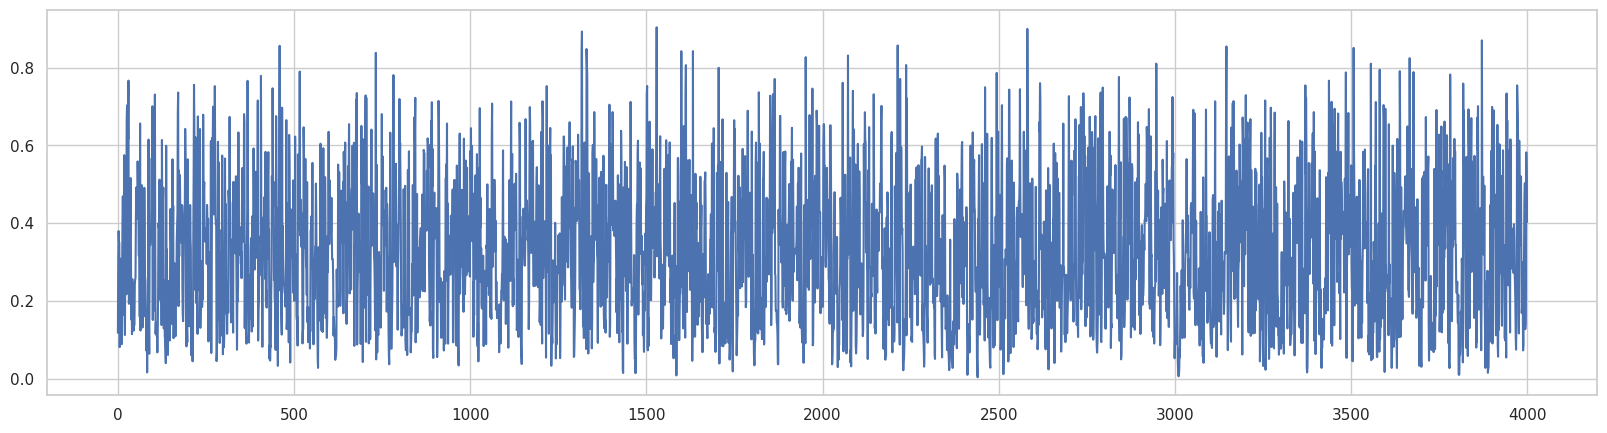

In [35]:
plt.plot(theta_draws)

<Axes: ylabel='Density'>

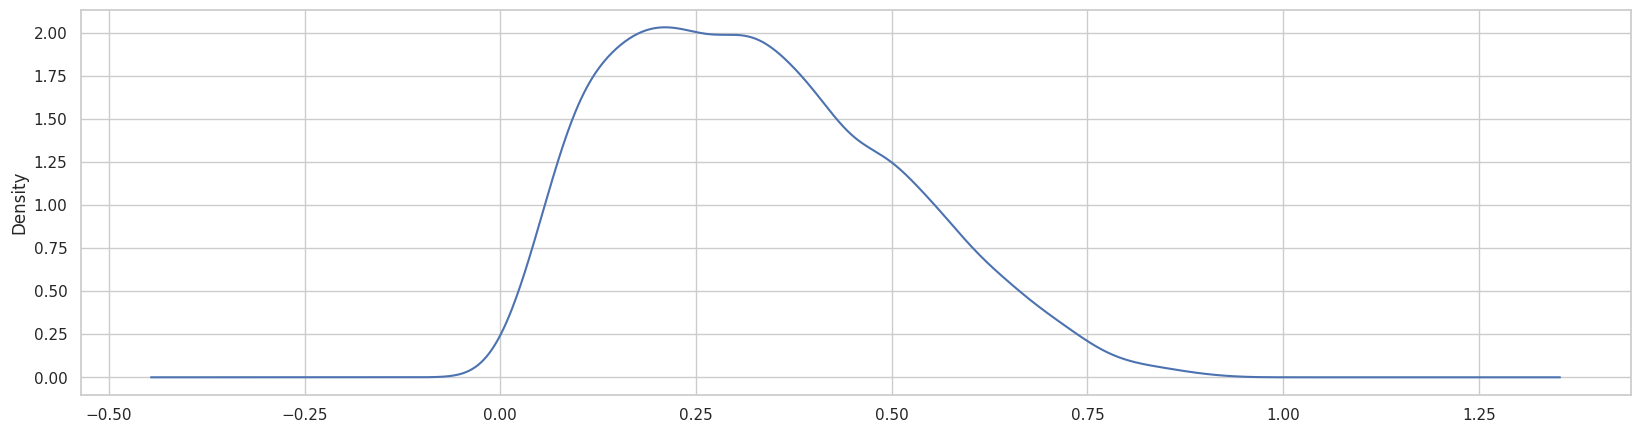

In [36]:
theta_draws.plot(kind="kde")

## Cell 4.3: Picking the best theta

**Goal**
- Combine the loss function from Cell 4.1 with the posterior samples to
  pick the loss-minimizing point estimate, for both the `N=4` and
  `N=20` posteriors

**Implementation** `pick_best_theta(idata)`
- Searches over candidate `theta` values and reports the one minimizing
  the expected loss under the posterior in `idata`

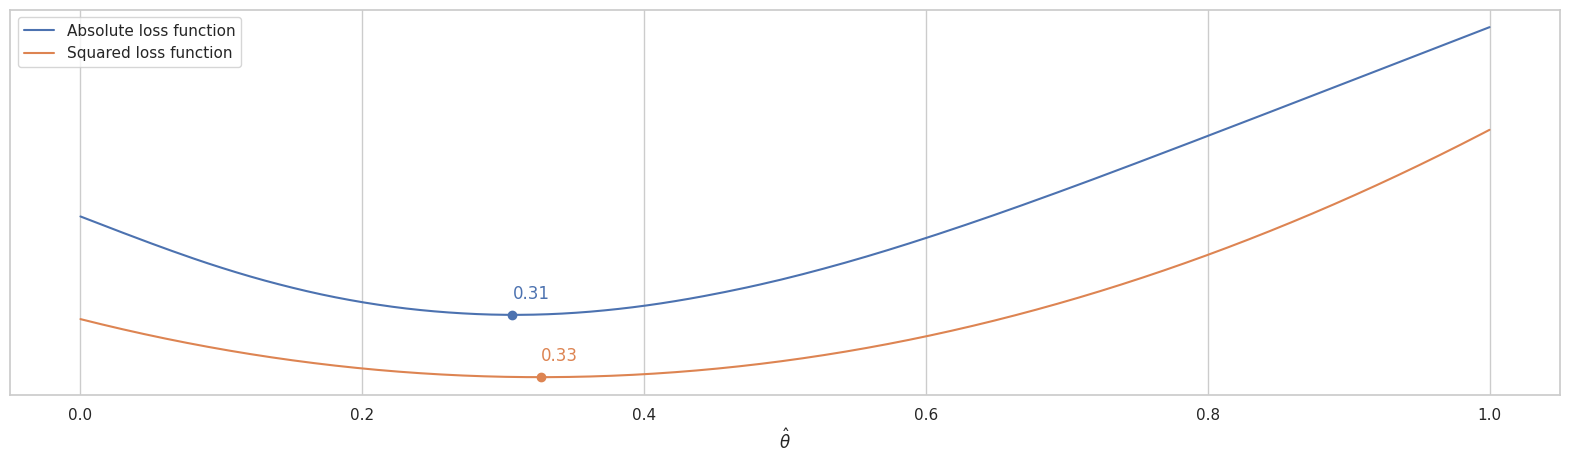

In [37]:
utils.pick_best_theta(idata1)

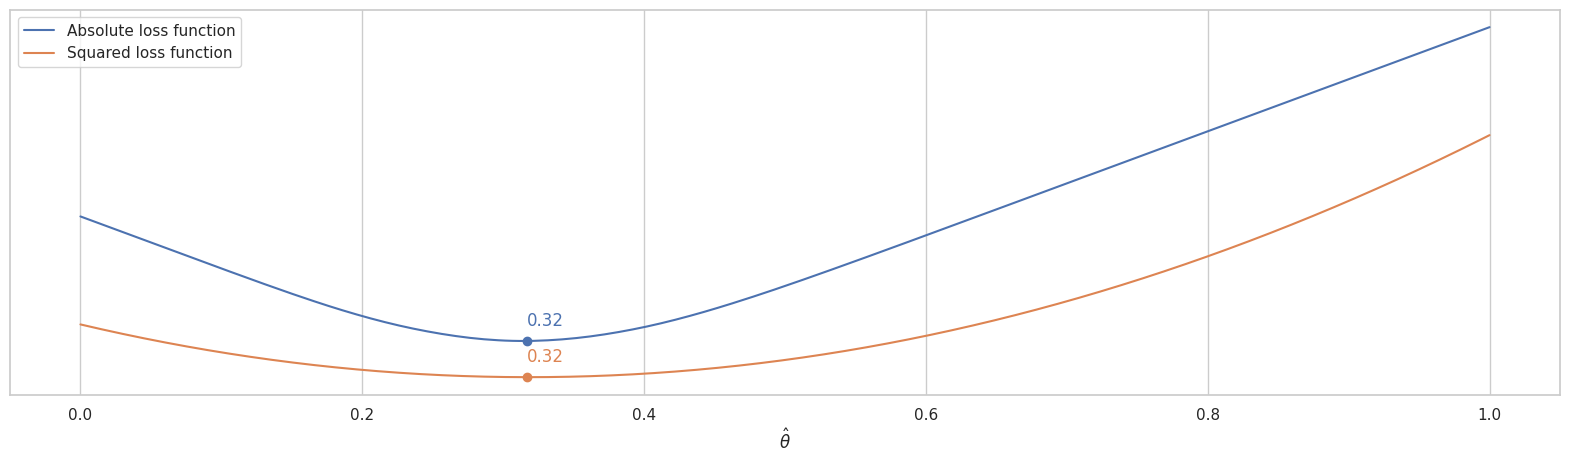

In [38]:
utils.pick_best_theta(idata2)